# Chunking Strategies

Before a document can be retrieved for RAG, it has to be split into chunks. This notebook
runs every chunking method of the book section *Chunking Strategies* on the same running
document, the Project Gutenberg edition of *A Study in Scarlet*, and reproduces the chunk-size
distributions of the book. It then asks the question the histograms cannot answer: which
strategy actually retrieves the answers to our questions?

**Learning goals:**
- Apply fixed-size, sentence, structural, semantic, and hierarchical chunking with LangChain
- Read a chunk-size distribution and spot tiny or oversized chunks
- Merge small chunks into substantial ones, by size and by meaning
- Retrieve on small chunks and hand the larger parent to the generator
- Compare strategies by answer recall at $k$ and by the context they cost

**Prerequisites:** Chapter 3 (sentence segmentation, tokens), Chapter 5 (sentence embeddings, cosine similarity)

## Setup

In [1]:
import os
import re

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"

import nltk
import numpy as np
import matplotlib.pyplot as plt
import tiktoken
from sentence_transformers import SentenceTransformer
from transformers.utils import logging as hf_logging
from langchain_text_splitters import (
    CharacterTextSplitter,
    NLTKTextSplitter,
    RecursiveCharacterTextSplitter,
    MarkdownHeaderTextSplitter,
)

from shared.display import print_table, display_md
from shared.data import load_gutenberg_book
from ch07_chunking import (
    size_stats, stats_rows, plot_sizes, merge_small,
    add_sentence_overlap, semantic_split, fold_small_chunks, to_markdown,
    embed, embed_queries, top_k, answer_recall, boundary_cohesion,
)

nltk.download("punkt_tab", quiet=True)
hf_logging.set_verbosity_error()      # we count tokens of long texts on purpose

The embedding model is used three times in this notebook: to show why long chunks blur, to
measure similarity in semantic splitting, and to retrieve chunks in the final comparison. We
use the book's model, all-MiniLM-L6-v2 (384 dimensions, about 90 MB download), which runs
on a laptop CPU.

In [2]:
EMBED_MODEL = "all-MiniLM-L6-v2"
SEMANTIC_THRESHOLD = 0.2      # merge neighbours only above this similarity (the book's value)

model = SentenceTransformer(EMBED_MODEL)
display_md(
    f"**{EMBED_MODEL}** on `{model.device}`: "
    f"{model.get_embedding_dimension()} dimensions, "
    f"reads at most {model.max_seq_length:,} tokens"
)

**all-MiniLM-L6-v2** on `cpu`: 384 dimensions, reads at most 256 tokens

## The Running Document

We load the novel from Project Gutenberg (book 244). The first run downloads it and caches it
under `data/gutenberg/`; the loader removes the Gutenberg license header and footer.

In [3]:
book = load_gutenberg_book(244)
text = book.page_content
enc = tiktoken.get_encoding("cl100k_base")    # the GPT-3.5/4 tokenizer of the book's note

display_md(
    f"| *{book.metadata['title']}* by {book.metadata['author']} | |\n|---|---|\n"
    f"| Characters | {len(text):,} |\n"
    f"| Words | {len(text.split()):,} |\n"
    f"| Tokens (GPT-3.5/4 tokenizer) | {len(enc.encode(text)):,} |\n"
    f"| Tokens ({EMBED_MODEL}) | {len(model.tokenizer(text)['input_ids']):,} |"
)

| *A Study in Scarlet* by Doyle, Arthur Conan | |
|---|---|
| Characters | 239,369 |
| Words | 43,427 |
| Tokens (GPT-3.5/4 tokenizer) | 57,842 |
| Tokens (all-MiniLM-L6-v2) | 55,883 |

### Characters, tokens, and words

Chunk sizes below are in characters, because LangChain's splitters count characters. Models
count tokens. The chapter introduction compares one sentence in English and Italian:

In [4]:
pair = {
    "English": "Information retrieval finds the documents that answer a question.",
    "Italian": "Il recupero delle informazioni trova i documenti che rispondono a una domanda.",
}
rows = []
for lang, s in pair.items():
    words, tokens = len(s.split()), len(enc.encode(s))
    rows.append([lang, words, tokens, f"{tokens / words:.2f}",
                 len(model.tokenizer.tokenize(s))])
print_table(rows, ["Language", "Words", "Tokens (GPT-3.5/4)", "Tokens per word",
                   f"Tokens ({EMBED_MODEL.split('/')[-1]})"])

| Language   |   Words |   Tokens (GPT-3.5/4) |   Tokens per word |   Tokens (all-MiniLM-L6-v2) |
|:-----------|--------:|---------------------:|------------------:|----------------------------:|
| English    |       9 |                   10 |              1.11 |                          10 |
| Italian    |      12 |                   21 |              1.75 |                          23 |

The same meaning costs about twice the tokens in Italian. A fixed token budget, whether a
chunk size or a context window, holds less text in some languages than in others. Each
model has its own tokenizer, so measure chunk sizes with the tokenizer of the model you use.

## Why Chunk at All?

Embed a whole chapter as one vector and a query for one fact must compete with everything
else the chapter says. We take the chapter that contains the word written in blood and compare
the query's similarity to the chapter as a whole with its similarity to the best paragraph
inside it.

In [5]:
query = "What word was written in blood on the wall?"
chapters = [c.strip() for c in re.split(r"\n{4,}", text) if c.strip()]
chapter = next(c for c in chapters if "RACHE" in c)
paragraphs_in_chapter = [p.strip() for p in chapter.split("\n\n") if p.strip()]

q = embed_queries([query], model)[0]
chapter_score = float(embed([chapter], model)[0] @ q)
para_emb = embed(paragraphs_in_chapter, model)
best = int(np.argmax(para_emb @ q))
chapter_tokens = len(model.tokenizer(chapter)["input_ids"])

display_md(
    f"**Query:** {query}\n\n"
    f"| Unit | Length | Similarity |\n|---|---|---|\n"
    f"| Whole chapter ({chapter.splitlines()[0]}) | {len(chapter):,} characters, "
    f"{chapter_tokens:,} tokens | {chapter_score:.3f} |\n"
    f"| Best paragraph of that chapter | {len(paragraphs_in_chapter[best])} characters | "
    f"{float(para_emb[best] @ q):.3f} |\n\n"
    f"**Best paragraph:** {paragraphs_in_chapter[best][:300]}"
)

**Query:** What word was written in blood on the wall?

| Unit | Length | Similarity |
|---|---|---|
| Whole chapter (CHAPTER III.) | 21,418 characters, 5,079 tokens | 0.157 |
| Best paragraph of that chapter | 248 characters | 0.569 |

**Best paragraph:** I have remarked that the paper had fallen away in parts. In this
particular corner of the room a large piece had peeled off, leaving a
yellow square of coarse plastering. Across this bare space there was
scrawled in blood-red letters a single word—

The paragraph scores far higher than the chapter it sits in, for two reasons. A chapter
vector averages over a crime scene, a cab, a constable, and a dozen other things, so a query
for one fact drowns in the rest. And all-MiniLM-L6-v2 reads only the first 256 of the
chapter's thousands of tokens, so the "chapter" embedding never even sees the wall. Splitting
into chunks fixes both problems.

## Fixed-Size Splitting

The book's first method packs words into chunks of at most 1000 characters, with 200
characters of overlap between neighbours.

In [6]:
text_splitter = CharacterTextSplitter(
    separator=" ",          # break on word boundaries
    chunk_size=1000,        # target characters per chunk
    chunk_overlap=200,      # characters shared between neighbours
)
fixed = text_splitter.split_text(text)

rows, headers = stats_rows({"Fixed-size (1000, overlap 200)": fixed})
print_table(rows, headers)

| Strategy                       |   Chunks |   Mean |   Median |   Min |   Max | Under 200   |
|:-------------------------------|---------:|-------:|---------:|------:|------:|:------------|
| Fixed-size (1000, overlap 200) |      299 |    996 |      997 |   889 |  1000 | 0%          |

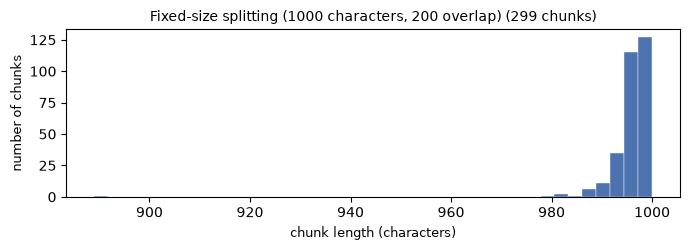

In [7]:
plot_sizes({"Fixed-size splitting (1000 characters, 200 overlap)": fixed})

Every chunk lands just below the limit; the splitter only stops early to keep the last word
whole. The overlap is visible where two neighbours meet: the end of one chunk reappears at the
start of the next.

In [8]:
a, b = fixed[40], fixed[41]
shared = next(a[i:] for i in range(len(a)) if b.startswith(a[i:]))
display_md(
    f"**End of chunk 40:** ...{a[-260:]}\n\n"
    f"**Start of chunk 41:** {b[:260]}...\n\n"
    f"**Shared text:** {len(shared)} characters"
)

**End of chunk 40:** ...learly in
Afghanistan.’ The whole train of thought did not occupy a second. I
then remarked that you came from Afghanistan, and you were astonished.”

“It is simple enough as you explain it,” I said, smiling. “You remind
me of Edgar Allen Poe’s Dupin. I had no

**Start of chunk 41:** a second. I
then remarked that you came from Afghanistan, and you were astonished.”

“It is simple enough as you explain it,” I said, smiling. “You remind
me of Edgar Allen Poe’s Dupin. I had no idea that such individuals did
exist outside of stories.”

Sherlo...

**Shared text:** 194 characters

Both boundaries fall in the middle of a sentence. The overlap guarantees that a sentence cut at
one boundary appears whole in one of the two chunks, at the price of storing and embedding
about 20% of the text twice.

A second problem hides in the units. The chunks are 1000 characters, but the embedding model
reads tokens and has a maximum input length.

In [9]:
tok_len = [len(model.tokenizer(c)["input_ids"]) for c in fixed]
over = sum(n > model.max_seq_length for n in tok_len)
display_md(
    f"Fixed-size chunks are **{np.mean(tok_len):.0f} tokens** on average "
    f"(maximum {max(tok_len)}). **{over} of {len(fixed)}** chunks exceed the "
    f"{model.max_seq_length:,}-token input window of {EMBED_MODEL} and are silently truncated."
)

Fixed-size chunks are **235 tokens** on average (maximum 295). **38 of 299** chunks exceed the 256-token input window of all-MiniLM-L6-v2 and are silently truncated.

A 1000-character chunk is right at the 256-token limit of all-MiniLM-L6-v2, and the chunks
above it lose their last sentences without any warning: the text is stored, but its end never
reaches the embedding, so a query about it cannot match. Larger models read further (Qwen3
embeddings, for example, read 32,768 tokens). This is the book's warning in practice: set
chunk sizes in the tokens of the model you use, not in characters.

## Sentence Boundaries

Splitting on every period would break on abbreviations. A trained segmenter such as Punkt
knows that "Dr." and "Mr." rarely end a sentence. We test it on the line where Watson meets
Holmes, once as printed in the book, with curly quotes, and once with straight quotes.

In [10]:
printed = "“Dr. Watson, Mr. Sherlock Holmes,” said Stamford, introducing us."
straight = printed.replace("“", '"').replace("”", '"')
rows = [[label, i + 1, s]
        for label, line in [("curly quotes", printed), ("straight quotes", straight)]
        for i, s in enumerate(nltk.sent_tokenize(line))]
print_table(rows, ["Version", "#", "Sentence"])

| Version         |   # | Sentence                                                          |
|:----------------|----:|:------------------------------------------------------------------|
| curly quotes    |   1 | “Dr.                                                              |
| curly quotes    |   2 | Watson, Mr. Sherlock Holmes,” said Stamford, introducing us.      |
| straight quotes |   1 | "Dr. Watson, Mr. Sherlock Holmes," said Stamford, introducing us. |

With straight quotes the segmenter keeps the line whole. With the curly quote in front of
"Dr.", it no longer recognizes the abbreviation and cuts after it. Punkt learned its
abbreviations from text with other conventions; the novel's typography is enough to fool it.
For chunking the damage is small, since the splitter packs many sentences into one chunk and
a false boundary only matters if it falls at the chunk's edge. It is a reminder to look at
the segmenter's output on your own documents.

The Gutenberg text is hard-wrapped at about 70 characters, so a sentence often spans several
lines. We flatten the line breaks first; they are layout, not structure. Then the book's
`NLTKTextSplitter` adds whole sentences to a chunk until the next one would overflow it.

In [11]:
flat = re.sub(r"\s+", " ", text).strip()

text_splitter = NLTKTextSplitter(chunk_size=1000, chunk_overlap=200)
sentence_chunks = text_splitter.split_text(flat)
raw_count = len(text_splitter.split_text(text))

rows, headers = stats_rows({"Sentence (NLTK, 1000, overlap 200)": sentence_chunks})
print_table(rows, headers)
display_md(f"On the unflattened text the same splitter returns {raw_count} chunks.")

| Strategy                           |   Chunks |   Mean |   Median |   Min |   Max | Under 200   |
|:-----------------------------------|---------:|-------:|---------:|------:|------:|:------------|
| Sentence (NLTK, 1000, overlap 200) |      299 |    929 |      949 |   558 |  1000 | 0%          |

On the unflattened text the same splitter returns 300 chunks.

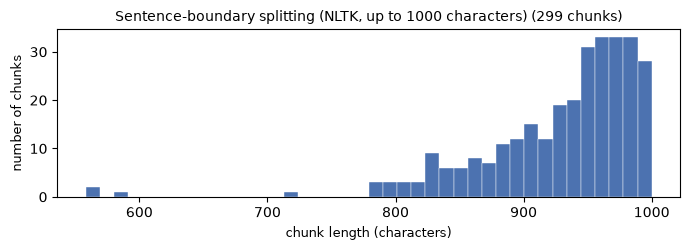

In [12]:
plot_sizes({"Sentence-boundary splitting (NLTK, up to 1000 characters)": sentence_chunks})

The spread is wider than for fixed-size splitting: a chunk closes as soon as the next whole
sentence would not fit, and sentence lengths vary. In exchange, no chunk starts or ends
mid-sentence.

## Splitting on Structure

In the Gutenberg text, more consecutive newlines mean a larger break: four newlines separate
chapters, two separate paragraphs.

In [13]:
chapters = [c.strip() for c in re.split(r"\n{4,}", text) if c.strip()]
paragraphs = [p.strip() for p in re.split(r"\n{2,}", text) if p.strip()]

rows, headers = stats_rows({"Chapters": chapters, "Paragraphs": paragraphs})
print_table(rows, headers)

| Strategy   |   Chunks |   Mean |   Median |   Min |   Max | Under 200   |
|:-----------|---------:|-------:|---------:|------:|------:|:------------|
| Chapters   |       19 |  12594 |    14380 |    19 | 23369 | 21%         |
| Paragraphs |      816 |    291 |      163 |     5 |  1792 | 58%         |

Neither level works on its own. Chapters are huge, and the handful of tiny ones are front
matter and part titles. Paragraphs are many and mostly tiny, because *A Study in Scarlet* is
written as dialogue: a paragraph is often one line of speech.

In [14]:
dialogue = [p for p in paragraphs[300:340] if len(p) < 120][:6]
print_table([[len(p), p] for p in dialogue], ["Characters", "Paragraph"])

|   Characters | Paragraph                                                              |
|-------------:|:-----------------------------------------------------------------------|
|            5 | “No.”                                                                  |
|            6 | “Why?”                                                                 |
|          117 | “Look at this advertisement,” he answered. “I had one sent to every    |
|              | paper this morning immediately after the affair.”                      |
|           80 | “That is all right,” I answered. “But supposing anyone applies, I have |
|              | no ring.”                                                              |
|           96 | “Oh yes, you have,” said he, handing me one. “This will do very well.  |
|              | It is almost a facsimile.”                                             |
|           55 | “And who do you expect will answer this advertisement.”                |

The fix is to merge. We keep the paragraph boundaries but join adjacent small paragraphs until
a chunk reaches about 1000 characters.

In [15]:
merged = merge_small(paragraphs, max_size=1000)

rows, headers = stats_rows({"Chapters": chapters, "Paragraphs": paragraphs,
                            "Paragraphs merged to ~1000": merged})
print_table(rows, headers)

| Strategy                   |   Chunks |   Mean |   Median |   Min |   Max | Under 200   |
|:---------------------------|---------:|-------:|---------:|------:|------:|:------------|
| Chapters                   |       19 |  12594 |    14380 |    19 | 23369 | 21%         |
| Paragraphs                 |      816 |    291 |      163 |     5 |  1792 | 58%         |
| Paragraphs merged to ~1000 |      284 |    839 |      855 |   217 |  1792 | 0%          |

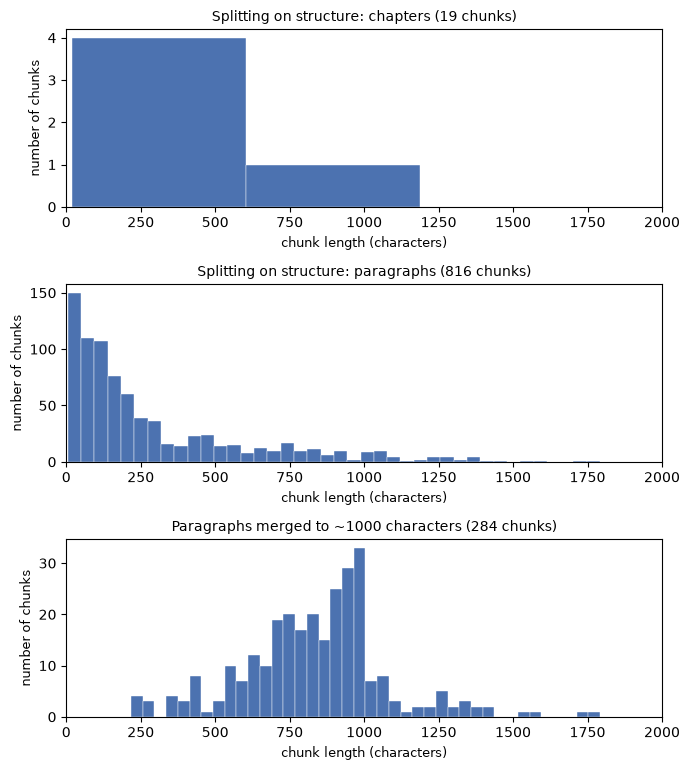

In [16]:
plot_sizes({
    "Splitting on structure: chapters": chapters,
    "Splitting on structure: paragraphs": paragraphs,
    "Paragraphs merged to ~1000 characters": merged,
}, xmax=2000)

Merging clears out the dialogue fragments and centres the distribution in the 800 to 1000
range. A few paragraphs are longer than the cap on their own and stay as they are.

**The LangChain version.** The book's code uses `RecursiveCharacterTextSplitter` with the two
separators. Note what it actually does: it does not return one chunk per structural unit. It
splits on the separators and then packs the pieces greedily up to `chunk_size`, so it merges
small paragraphs on its own, just with a larger cap.

In [17]:
text_splitter = RecursiveCharacterTextSplitter(
    separators=["\n\n\n\n", "\n\n"],  # four newlines = chapter, two = paragraph
    chunk_size=2000,
    chunk_overlap=0,
)
structural = text_splitter.split_text(text)

rows, headers = stats_rows({"RecursiveCharacterTextSplitter (2000)": structural})
print_table(rows, headers)

| Strategy                              |   Chunks |   Mean |   Median |   Min |   Max | Under 200   |
|:--------------------------------------|---------:|-------:|---------:|------:|------:|:------------|
| RecursiveCharacterTextSplitter (2000) |      149 |   1604 |     1694 |    37 |  1998 | 1%          |

**Overlap for structural chunks.** A fixed character overlap works poorly when a single
paragraph can be longer than the overlap window. The book's alternative carries the last
sentence of the previous chunk and the first sentence of the next one into each chunk.

In [18]:
with_overlap = add_sentence_overlap([re.sub(r"\s+", " ", c) for c in merged])
i = 120
display_md(
    f"**Chunk {i} without overlap** ({len(merged[i])} characters) starts:\n\n"
    f"> {re.sub(chr(10), ' ', merged[i][:160])}...\n\n"
    f"**With sentence overlap** ({len(with_overlap[i])} characters) starts with the last "
    f"sentence of chunk {i - 1}:\n\n> {with_overlap[i][:300]}..."
)

**Chunk 120 without overlap** (970 characters) starts:

> It was indeed Lestrade, who had ascended the stairs while we were talking, and who now entered the room. The assurance and jauntiness which generally marked his...

**With sentence overlap** (1142 characters) starts with the last sentence of chunk 119:

> Why, by Jove, here’s the very man himself!” It was indeed Lestrade, who had ascended the stairs while we were talking, and who now entered the room. The assurance and jauntiness which generally marked his demeanour and dress were, however, wanting. His face was disturbed and troubled, while his clot...

## Semantic Splitting

Structural splitting needs reliable structure. Semantic splitting groups sentences by meaning
instead. We start from groups of about 100 characters, embed them, and repeatedly merge the
most similar neighbours while the result stays under 1000 characters.

First a look at the signal it uses: the similarity between each sentence group and the next.
A dip marks a change of topic.

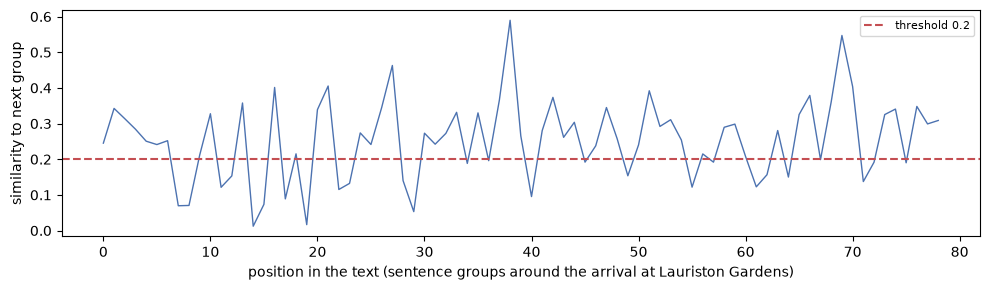

In [19]:
groups = merge_small(nltk.sent_tokenize(flat), max_size=100)
start = next(i for i, g in enumerate(groups) if "Lauriston Gardens wore" in g) - 30
window = groups[start:start + 80]
emb = embed(window, model)
sims = [float(emb[i] @ emb[i + 1]) for i in range(len(window) - 1)]

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(sims, color="#4C72B0", linewidth=1)
ax.axhline(SEMANTIC_THRESHOLD, color="#C44E52", linestyle="--",
           label=f"threshold {SEMANTIC_THRESHOLD}")
ax.set_xlabel("position in the text (sentence groups around the arrival at Lauriston Gardens)")
ax.set_ylabel("similarity to next group")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Adjacent groups above the threshold are candidates for merging; a pair below it is never
merged and stays a boundary. With 0.2, about 29% of adjacent pairs fall below the line. The
threshold is a property of the model: a model that scores all sentence pairs higher needs a
higher number for the same cut, so when you switch models, set the threshold at the same
percentile of adjacent similarities rather than at the same value.

In [20]:
sentences = nltk.sent_tokenize(flat)
semantic = semantic_split(sentences, model, threshold=SEMANTIC_THRESHOLD, max_size=1000)

rows, headers = stats_rows({"Semantic": semantic})
print_table(rows, headers)

| Strategy   |   Chunks |   Mean |   Median |   Min |   Max | Under 200   |
|:-----------|---------:|-------:|---------:|------:|------:|:------------|
| Semantic   |      491 |    485 |      537 |    14 |  1000 | 30%         |

The chunks spread across the whole size range instead of piling up at the limit, because a
boundary falls wherever the topic shifts. The cost is a residue of very small chunks: a
sentence that resembles neither neighbour is never merged. A second pass folds each chunk
under 200 characters into its semantically closer neighbour, regardless of the threshold.

In [21]:
semantic_clean = fold_small_chunks(semantic, model, small=200)

rows, headers = stats_rows({"Semantic": semantic, "Semantic, small chunks folded": semantic_clean})
print_table(rows, headers)

| Strategy                      |   Chunks |   Mean |   Median |   Min |   Max | Under 200   |
|:------------------------------|---------:|-------:|---------:|------:|------:|:------------|
| Semantic                      |      491 |    485 |      537 |    14 |  1000 | 30%         |
| Semantic, small chunks folded |      355 |    671 |      670 |   205 |  1167 | 0%          |

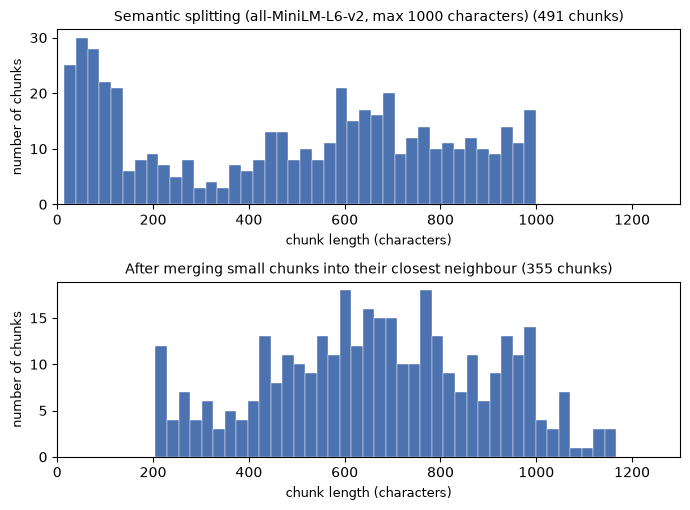

In [22]:
plot_sizes({
    f"Semantic splitting ({EMBED_MODEL.split('/')[-1]}, max 1000 characters)": semantic,
    "After merging small chunks into their closest neighbour": semantic_clean,
}, xmax=1300)

The fold removes every chunk under 200 characters and moves the median into the mid-range. A
few chunks run past 1000, where a fragment joined an already full neighbour.

## Hierarchical Chunking

Every method so far picks one chunk size. Hierarchical chunking keeps two: split coarsely by
headings, then finely within each section, and store both. To use the book's code we first
mark the PART and CHAPTER lines as Markdown headings.

In [23]:
long_markdown_text = to_markdown(text)

header_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=[("#", "H1"), ("##", "H2"), ("###", "H3")]
)
sections = header_splitter.split_text(long_markdown_text)

token_splitter = RecursiveCharacterTextSplitter(chunk_size=512, chunk_overlap=50)
final_chunks = []
for sec in sections:
    for idx, sub in enumerate(token_splitter.split_text(sec.page_content)):
        final_chunks.append({
            "content": sub,
            "metadata": {**sec.metadata, "sub_chunk": idx},
        })

display_md(
    f"**{len(sections)} sections** (parents), **{len(final_chunks)} sub-chunks** "
    f"(children, median {size_stats([c['content'] for c in final_chunks])['median']} characters)"
)

**17 sections** (parents), **511 sub-chunks** (children, median 480 characters)

Retrieval runs against the small children; their metadata leads back to the parent section.

In [24]:
children = [c["content"] for c in final_chunks]
child_emb = embed(children, model)
section_of = {(s.metadata.get("H1"), s.metadata.get("H2")): s.page_content for s in sections}

def parent_of(chunk):
    m = chunk["metadata"]
    return section_of[(m.get("H1"), m.get("H2"))]

q = embed_queries(["Which constable found the body in the empty house?"], model)[0]
rows = []
for i in top_k(q, child_emb, k=3):
    c = final_chunks[i]
    rows.append([c["metadata"].get("H2", c["metadata"].get("H1")), c["metadata"]["sub_chunk"],
                 len(c["content"]), f"{len(parent_of(c)):,}", c["content"][:120] + "..."])
print_table(rows, ["Parent section", "Sub-chunk", "Child chars", "Parent chars", "Child text"])

| Parent section                                   |   Sub-chunk |   Child chars |   Parent chars | Child text                                                              |
|:-------------------------------------------------|------------:|--------------:|---------------:|:------------------------------------------------------------------------|
| CHAPTER VI. TOBIAS GREGSON SHOWS WHAT HE CAN DO. |          34 |           456 |         17,981 | his victim into the empty house. As to the candle, and the blood, and   |
|                                                  |             |               |                | the writing on the wall, and the ring, they may al...                   |
| CHAPTER III. THE LAURISTON GARDENS MYSTERY       |          14 |           510 |         21,471 | bounded by a three-foot brick wall with a fringe of wood rails upon the |
|                                                  |             |               |                | top, and against this wall was leaning a stalwar...                     |
| CHAPTER IV. WHAT JOHN RANCE HAD TO TELL.         |          13 |           486 |         13,557 | the line of dead-coloured brick. “You’ll find me here when you come     |
|                                                  |             |               |                | back.”                                                                  |
|                                                  |             |               |                | Audley Court was not an attractive locality...                          |

The best children are short passages about the empty house, the constable, and the writing on
the wall, and each one leads to its whole chapter. The answer itself ("John Rance") is not in
the top child, but the parent chapter of the third hit is about him: a small child found the
place, the parent supplies the context. Here the parents are chapters of 10,000 to 23,000 characters, which is a lot of
context per hit. A more focused parent level is the structural split from above: the
2000-character chunks of `RecursiveCharacterTextSplitter`, each split again into small
children.

In [25]:
parents = structural                                   # ~1600 characters on average
child_splitter = RecursiveCharacterTextSplitter(chunk_size=512, chunk_overlap=50)
focused_children, focused_parent = [], []
for p_id, p in enumerate(parents):
    for sub in child_splitter.split_text(p):
        focused_children.append(sub)
        focused_parent.append(p_id)

rows, headers = stats_rows({"Focused parents": parents, "Their children": focused_children})
print_table(rows, headers)

| Strategy        |   Chunks |   Mean |   Median |   Min |   Max | Under 200   |
|:----------------|---------:|-------:|---------:|------:|------:|:------------|
| Focused parents |      149 |   1604 |     1694 |    37 |  1998 | 1%          |
| Their children  |      671 |    356 |      427 |    20 |   510 | 20%         |

## Query-Aware Chunking

The two levels also let us decide **after** seeing the query how much context to send. A
factual question gets the best one or two children; a summary request gets the parent section
of the best match. In a real system, intent detection (Chapter 3) or the agent itself sets the
intent; here we pass it in.

In [26]:
def assemble_context(query: str, intent: str) -> list[str]:
    """Return the context passages for a query, sized to its intent."""
    q = embed_queries([query], model)[0]
    hits = top_k(q, child_emb, k=2)
    if intent == "factual":
        return [children[i] for i in hits]
    return [parent_of(final_chunks[hits[0]])]           # "summary": the whole section

rows = []
for query, intent in [("Which constable found the body in the empty house?", "factual"),
                      ("Summarize what John Rance told Holmes.", "summary")]:
    ctx = assemble_context(query, intent)
    rows.append([query, intent, len(ctx), f"{sum(map(len, ctx)):,}", ctx[0][:90] + "..."])
print_table(rows, ["Query", "Intent", "Passages", "Characters", "Context starts"])

| Query                                              | Intent   |   Passages |   Characters | Context starts                                                        |
|:---------------------------------------------------|:---------|-----------:|-------------:|:----------------------------------------------------------------------|
| Which constable found the body in the empty house? | factual  |          2 |          966 | his victim into the empty house. As to the candle, and the blood, and |
|                                                    |          |            |              | the writing on the w...                                               |
| Summarize what John Rance told Holmes.             | summary  |          1 |       13,557 | It was one o’clock when we left No. 3, Lauriston Gardens. Sherlock    |
|                                                    |          |            |              | Holmes led me to the ne...                                            |

Same index, same retrieval, more than ten times the context for the summary. The factual question
stays cheap, and the summary gets the room it needs.

## Which Strategy Is Best?

A histogram tells us about sizes, not about answers. The dependable test holds the retriever
fixed and varies only the chunking: for a set of questions with known answers, does the top
$k$ contain the answer? We use 19 questions about the novel, each with a short answer string
that appears in only a few places in the text. They are worded differently from the text, so
exact word overlap does not find them.

In [27]:
QUESTIONS = [
    ("Where was Watson wounded in battle?", "Maiwand"),
    ("Where did Watson train as an army surgeon?", "Netley"),
    ("Who introduced Watson to Sherlock Holmes?", "Stamford"),
    ("What pet does Watson say he keeps?", "bull pup"),
    ("Which famous writer had Holmes never heard of?", "Carlyle"),
    ("What is the address of the rooms Holmes and Watson share?", "221B"),
    ("What word was written in blood on the wall?", "RACHE"),
    ("What does the word on the wall mean in German?", "revenge"),
    ("What kind of cigar did the murderer smoke?", "Trichinopoly"),
    ("Which constable found the body in the empty house?", "John Rance"),
    ("What fell to the floor when the body was lifted?", "wedding ring"),
    ("Which street boy leads the Baker Street irregulars?", "Wiggins"),
    ("Where did Drebber lodge in London?", "Torquay Terrace"),
    ("Which city did Drebber and Stangerson visit before London?", "Copenhagen"),
    ("Where was Stangerson murdered?", "Halliday"),
    ("Who is the murderer of Enoch Drebber?", "Jefferson Hope"),
    ("What illness does the murderer suffer from?", "aneurism"),
    ("How did the murderer kill Drebber?", "pill"),
    ("Who leads the Mormon settlers in Utah?", "Brigham Young"),
]
answers = [a for _, a in QUESTIONS]
query_emb = embed_queries([q for q, _ in QUESTIONS], model)

For every strategy we embed its chunks, rank them by cosine similarity to each question, and
check the top $k$. A question counts as answered if at least one of its top $k$ chunks contains
the answer string; the match ignores case and line breaks. **Answer recall at $k$** is the share
of questions answered this way:

$$
\text{Recall@}k = \frac{1}{|Q|} \sum_{q \in Q} \mathbb{1}\big[\,a_q \in \text{top-}k(q)\,\big]
$$

where $a_q$ is the answer string of question $q$. This is not the recall of Chapter 2
(Performance Evaluation), which counts how many of all relevant documents a query retrieves.
Here each question has one answer, and we only ask whether it arrived in the context;
information retrieval often calls this success at $k$ or hit rate.

We measure it at $k = 1, 3, 5$. **Context chars @3** is the mean number of characters that the
top 3 hand to the generator per question: the context cost. The two hierarchical rows match the
query against the children but test and count the parent the generator would receive; when two
children share a parent, that parent is sent and counted once.

In [28]:
strategies = {
    "Fixed-size (1000/200)": fixed,
    "Sentence (1000/200)": sentence_chunks,
    "Paragraphs": paragraphs,
    "Paragraphs merged": merged,
    "Semantic, folded": semantic_clean,
    "Children only (512/50)": focused_children,
}
chunk_emb = {name: embed(chunks, model) for name, chunks in strategies.items()}
focused_emb = chunk_emb["Children only (512/50)"]

def row(name, chunks, emb, context=None):
    r = [answer_recall(answers, query_emb, chunks, emb, k=k, context=context) for k in (1, 3, 5)]
    return [name, len(chunks)] + [f"{rec:.2f}" for rec, _ in r] + [f"{r[1][1]:,}"]

rows = [row(name, chunks, chunk_emb[name]) for name, chunks in strategies.items()]
rows.append(row("Children → focused parent", focused_children, focused_emb,
                context=[parents[p] for p in focused_parent]))
rows.append(row("Children → chapter", children, child_emb,
                context=[parent_of(c) for c in final_chunks]))
print_table(rows, ["Strategy", "Chunks", "Recall@1", "Recall@3", "Recall@5", "Context chars @3"])

| Strategy                  |   Chunks |   Recall@1 |   Recall@3 |   Recall@5 |   Context chars @3 |
|:--------------------------|---------:|-----------:|-----------:|-----------:|-------------------:|
| Fixed-size (1000/200)     |      299 |       0.21 |       0.42 |       0.53 |              2,988 |
| Sentence (1000/200)       |      299 |       0.37 |       0.42 |       0.42 |              2,759 |
| Paragraphs                |      816 |       0.26 |       0.32 |       0.42 |              1,339 |
| Paragraphs merged         |      284 |       0.37 |       0.53 |       0.53 |              2,722 |
| Semantic, folded          |      355 |       0.21 |       0.26 |       0.37 |              2,111 |
| Children only (512/50)    |      671 |       0.21 |       0.21 |       0.32 |              1,081 |
| Children → focused parent |      671 |       0.32 |       0.37 |       0.47 |              5,157 |
| Children → chapter        |      511 |       0.63 |       0.95 |       0.95 |             46,547 |

Three patterns stand out:

- **No flat strategy wins everywhere.** The strategies of about 1000 characters stay close to
  each other, and their order changes with $k$. Merged paragraphs do best, since they follow
  the author's own units. Semantic chunks do worst here, although their boundaries look the
  most natural in the next test: a boundary that follows a topic shift can still separate a
  question's clue from its answer.
- **Small children alone lose recall.** A 512-character child often holds the clue but not the
  answer word, which sits a few sentences away.
- **Children with parents recover it, at a price.** Returning the focused parent of about
  1600 characters lifts the children's recall at every $k$, into the range of the flat
  strategies but not above the best of them. Returning
  the whole chapter answers almost every question, but sends tens of thousands of characters
  per question, about ten times the focused parent, and the generator then has to find the
  answer in a long context. That is the trade-off of the book in numbers: sharp matching on
  small chunks, enough context from the parent, and a context budget that decides how large
  the parent may be.

With only 19 questions, one question is about 0.05 of recall, so small differences between
the flat strategies are noise. The large effects, children alone versus children with
chapters, are not.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Measure chunking on the task, not on the histogram</strong><br>
The tidiest size distribution is not the best chunking. Hold the retriever fixed, vary only the chunks, and count how often the top $k$ actually contains the answer, together with how much text it costs to send. The winner depends on your documents, your questions, and your context budget.
</div>

### A label-free smell test

Without labelled questions, the book suggests comparing the similarity of adjacent sentences
inside a chunk with the similarity across a chunk boundary. A good split keeps the first high
and lets the second drop. Chunks must not overlap for this, so we use the overlap-free versions.

In [29]:
no_overlap = {
    "Fixed-size (1000/0)": CharacterTextSplitter(separator=" ", chunk_size=1000,
                                                  chunk_overlap=0).split_text(text),
    "Sentence (1000/0)": NLTKTextSplitter(chunk_size=1000, chunk_overlap=0).split_text(flat),
    "Paragraphs merged": merged,
    "Semantic, folded": semantic_clean,
}
rows = []
for name, chunks in no_overlap.items():
    within, across = boundary_cohesion(chunks, model)
    rows.append([name, f"{within:.3f}", f"{across:.3f}", f"{within - across:+.3f}"])
print_table(rows, ["Strategy", "Within chunk", "Across boundary", "Gap"])

| Strategy            |   Within chunk |   Across boundary |    Gap |
|:--------------------|---------------:|------------------:|-------:|
| Fixed-size (1000/0) |          0.252 |             0.215 |  0.037 |
| Sentence (1000/0)   |          0.261 |             0.273 | -0.012 |
| Paragraphs merged   |          0.264 |             0.246 |  0.019 |
| Semantic, folded    |          0.279 |             0.177 |  0.103 |

Semantic splitting shows the largest gap, which is no surprise: it optimizes exactly this
quantity. The other three boundaries fall wherever the size runs out, or at a paragraph break
in the middle of a conversation, so the sentences across a boundary are about as similar as
those inside a chunk. That is why the smell test cannot replace the answer-recall test above:
semantic splitting has by far the cleanest boundaries and retrieved the fewest answers of the
flat strategies. A
strategy can score well on cohesion and still cut the answer away from its question.

## Summary

| Strategy | Unit | Strength | Weakness |
|---|---|---|---|
| Fixed-size | characters | uniform, fast | cuts sentences and topics |
| Sentence | sentences up to a cap | no broken sentences | ignores topic shifts |
| Structure | chapters, paragraphs | author's own units | sizes extreme, needs merging |
| Semantic | sentences grouped by meaning | boundaries follow topics | embedding cost, fragments to fold |
| Hierarchical | small children + larger parents | sharp matching and enough context | two levels to store and resolve |

The chunk size is a compromise between sharp embeddings and enough context. Two-level chunking
avoids the compromise, and the only reliable judge is answer recall on your own questions.

## Try it yourself

1. In the setup cell, switch to a larger model, for example `Qwen/Qwen3-Embedding-0.6B` with
   `SEMANTIC_THRESHOLD = 0.34` (a GPU is recommended). Which strategies gain most recall, and
   how many fixed-size chunks are still truncated?
2. Change `SEMANTIC_THRESHOLD` up and down by 0.1. How do the raw semantic chunk count and the
   share under 200 characters change, and does the fold still clean up?
3. Build the focused hierarchy with children of 256 instead of 512 characters. Does recall@1
   of "Children only" drop, and does "Children → focused parent" still recover it?